# COVID-19 Data Analysis – Project 2

### 1. Import libraries and load dataset

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('COVID-19_Coronavirus.csv')

### 2. Shape of the dataset

In [2]:
df.shape

(225, 10)

### 3. First five rows

In [3]:
df.head()

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271
4,Angola,Angola,AGO,34654212,Africa,99194,1900,2862,55,1.915438


### 4. Last five rows

In [4]:
df.tail()

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
220,Wallis and Futuna,Wallis and Futuna Islands,WLF,10894,Oceania,454,7,41674,643,1.541850
221,Western Sahara,Western Sahara,ESHÂ,623031,Africa,10,1,16,2,10.000000
222,Yemen,Yemen,YEM,30975258,Asia,11806,2143,381,69,18.151787
223,Zambia,Zambia,ZMB,19284482,Africa,317076,3967,16442,206,1.251120
224,Zimbabwe,Zimbabwe,ZWE,15241601,Africa,246525,5446,16174,357,2.209107


### 5. Dataset info

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 225 entries, 0 to 224
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Country                  225 non-null    str    
 1   Other names              224 non-null    str    
 2   ISO 3166-1 alpha-3 CODE  225 non-null    str    
 3   Population               225 non-null    int64  
 4   Continent                225 non-null    str    
 5   Total Cases              225 non-null    int64  
 6   Total Deaths             225 non-null    int64  
 7   Tot Cases//1M pop        225 non-null    int64  
 8   Tot Deaths/1M pop        225 non-null    int64  
 9   Death percentage         225 non-null    float64
dtypes: float64(1), int64(5), str(4)
memory usage: 17.7 KB


### 6. Missing values in each column

In [6]:
df.isnull().sum()

Country                    0
Other names                1
ISO 3166-1 alpha-3 CODE    0
Population                 0
Continent                  0
Total Cases                0
Total Deaths               0
Tot Cases//1M pop          0
Tot Deaths/1M pop          0
Death percentage           0
dtype: int64

### 7. Rows containing missing values

In [7]:
df[df.isnull().any(axis=1)]

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
135,Montenegro,NaN,MNE,628205,Europe,233326,2705,371417,4306,1.159322


### 8. Replace missing value with 'Montenegro'
Missing value 'Other names' column mein hai (Montenegro ka row).

In [8]:
df['Other names'] = df['Other names'].fillna('Montenegro')

### 9. Check row 135

In [9]:
df.loc[[135]]

,Country,Other names,ISO 3166-1 alpha-3 CODE,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
135,Montenegro,Montenegro,MNE,628205,Europe,233326,2705,371417,4306,1.159322


### 10. Descriptive statistics

In [10]:
df.describe()

,Population,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
count,2.250000e+02,2.250000e+02,2.250000e+02,225.000000,225.000000,225.000000
mean,3.507321e+07,2.184781e+06,2.744813e+04,136900.373333,1096.715556,1.444125
std,1.392418e+08,7.275938e+06,9.689177e+04,145060.340289,1195.715543,1.741728
min,8.050000e+02,1.000000e+00,0.000000e+00,9.000000,0.000000,0.000000
25%,5.665570e+05,2.407100e+04,1.890000e+02,11384.000000,123.000000,0.511291
50%,5.827911e+06,1.639360e+05,1.965000e+03,88987.000000,708.000000,1.036905
75%,2.190585e+07,1.092547e+06,1.366000e+04,223335.000000,1795.000000,1.977017
max,1.439324e+09,8.183905e+07,1.008222e+06,696044.000000,6286.000000,18.151787


### 11. Rename column and show first 4 rows

In [11]:
df = df.rename(columns={'ISO 3166-1 alpha-3 CODE': 'Iso_Code'})
df.head(4)

,Country,Other names,Iso_Code,Population,Continent,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
0,Afghanistan,Afghanistan,AFG,40462186,Asia,177827,7671,4395,190,4.313743
1,Albania,Albania,ALB,2872296,Europe,273870,3492,95349,1216,1.275058
2,Algeria,Algeria,DZA,45236699,Africa,265691,6874,5873,152,2.587216
3,Andorra,Andorra,AND,77481,Europe,40024,153,516565,1975,0.382271


### 12. Top 5 countries – highest total cases

In [12]:
top_cases = df.nlargest(5, 'Total Cases')[['Country','Total Cases']]
top_cases

,Country,Total Cases
214,USA,81839052
92,India,43029044
26,Brazil,29999816
70,France,25997852
76,Germany,21646375


### 13. Bar plot – highest cases

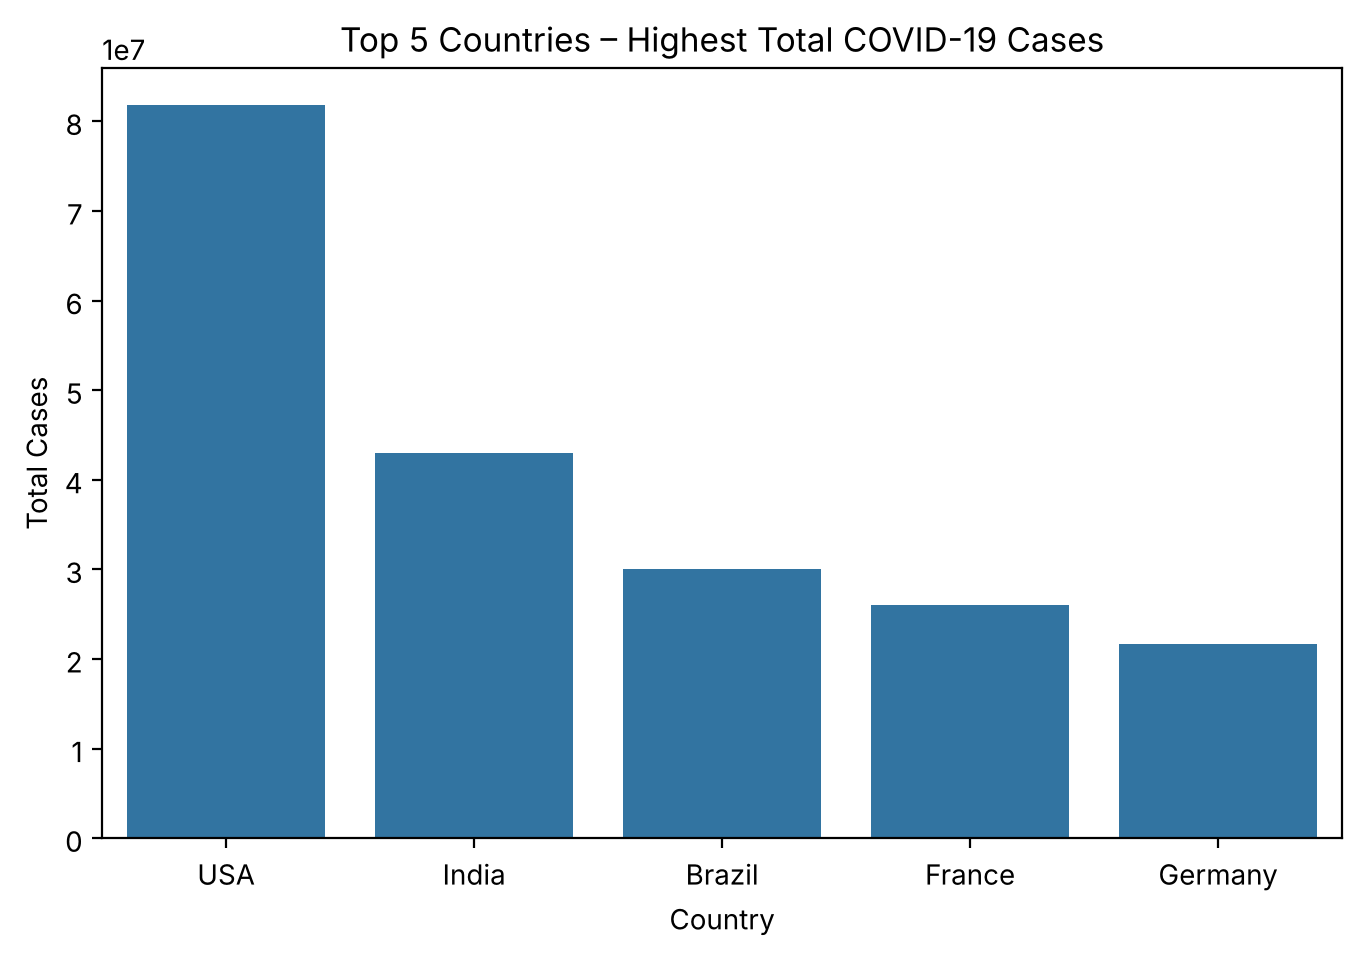

In [13]:
plt.figure(figsize=(8,5))
sns.barplot(x='Country', y='Total Cases', data=top_cases)
plt.title('Top 5 Countries – Highest Total COVID-19 Cases')
plt.show()

### 14. 5 countries – lowest total cases

In [14]:
low_cases = df.nsmallest(5, 'Total Cases')[['Country','Total Cases']]
low_cases

,Country,Total Cases
131,Micronesia,1
168,Saint Helena,2
125,Marshall Islands,7
148,Niue,7
221,Western Sahara,10


### 15. Bar plot – lowest cases

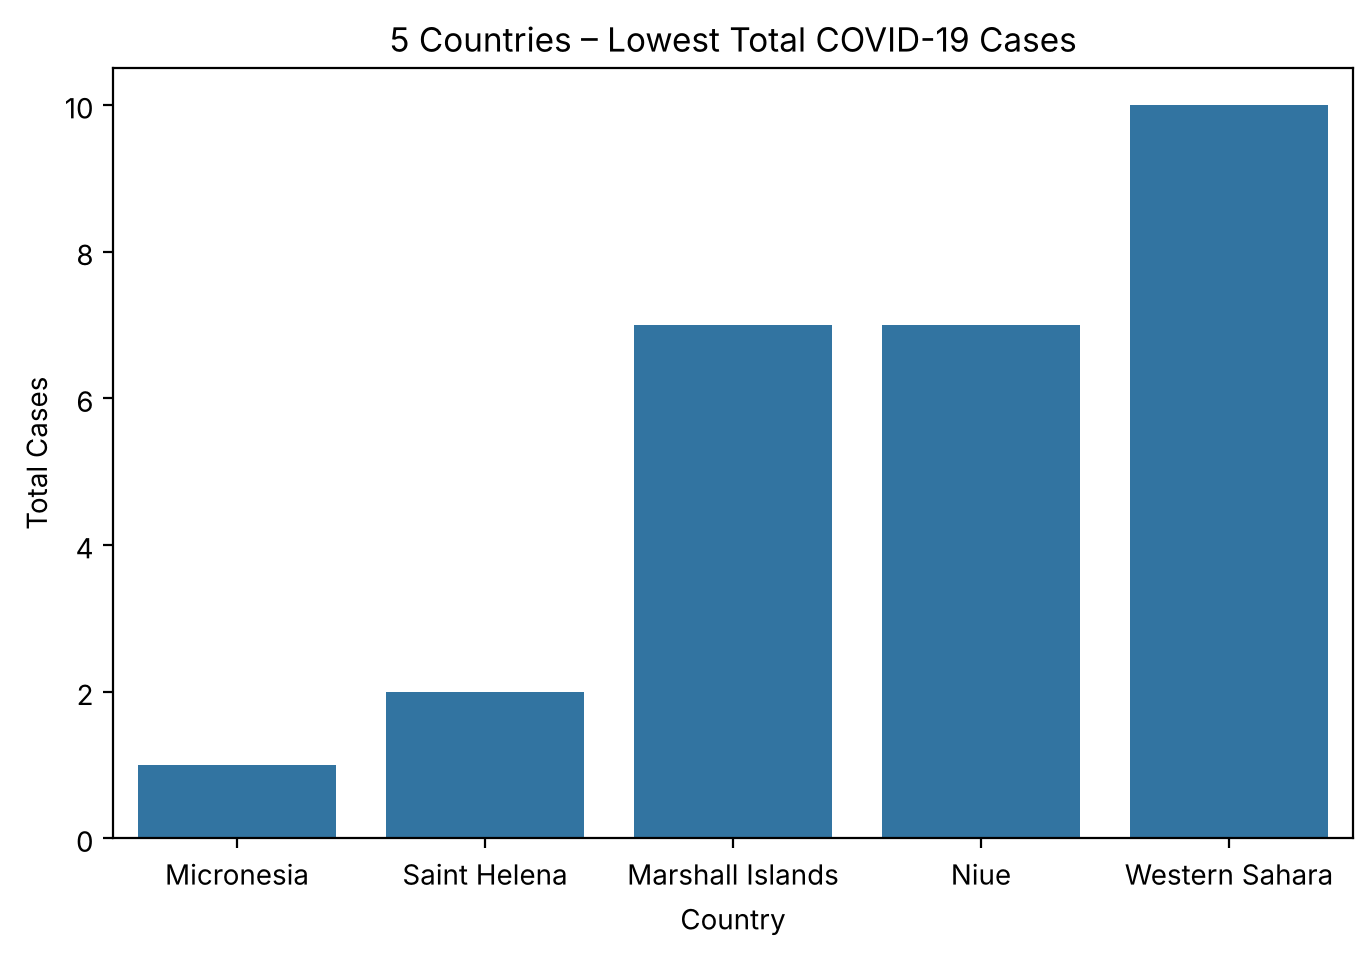

In [15]:
plt.figure(figsize=(8,5))
sns.barplot(x='Country', y='Total Cases', data=low_cases)
plt.title('5 Countries – Lowest Total COVID-19 Cases')
plt.show()

### 16. Top 5 – highest deaths

In [16]:
top_deaths = df.nlargest(5, 'Total Deaths')[['Country','Total Deaths']]
top_deaths

,Country,Total Deaths
214,USA,1008222
26,Brazil,660269
92,India,521388
165,Russia,369708
130,Mexico,323212


### 17. Bar plot – highest deaths

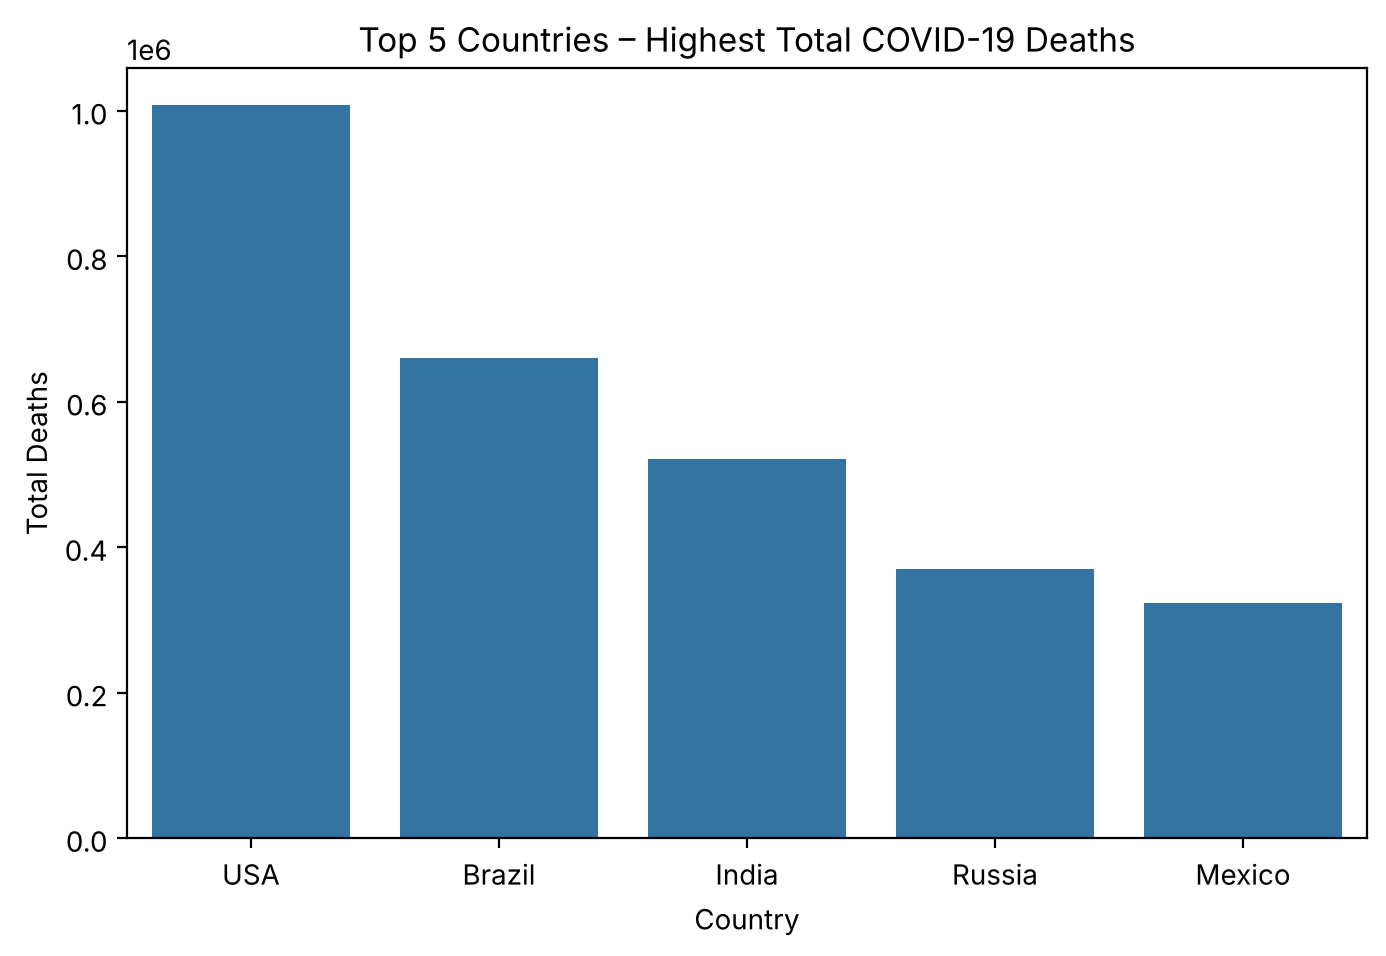

In [17]:
plt.figure(figsize=(8,5))
sns.barplot(x='Country', y='Total Deaths', data=top_deaths)
plt.title('Top 5 Countries – Highest Total COVID-19 Deaths')
plt.show()

### 18. 5 countries – lowest deaths

In [18]:
low_deaths = df.nsmallest(5, 'Total Deaths')[['Country','Total Deaths']]
low_deaths

,Country,Total Deaths
46,Cook Islands,0
67,Falkland Islands,0
118,Macao,0
125,Marshall Islands,0
131,Micronesia,0


### 19. Top 5 – highest death percentage

In [19]:
top_dp = df.nlargest(5, 'Death percentage')[['Country','Death percentage']]
top_dp

,Country,Death percentage
222,Yemen,18.151787
221,Western Sahara,10.000000
193,Sudan,7.920265
158,Peru,5.983499
130,Mexico,5.705041


### 20. Bar plot – highest death percentage

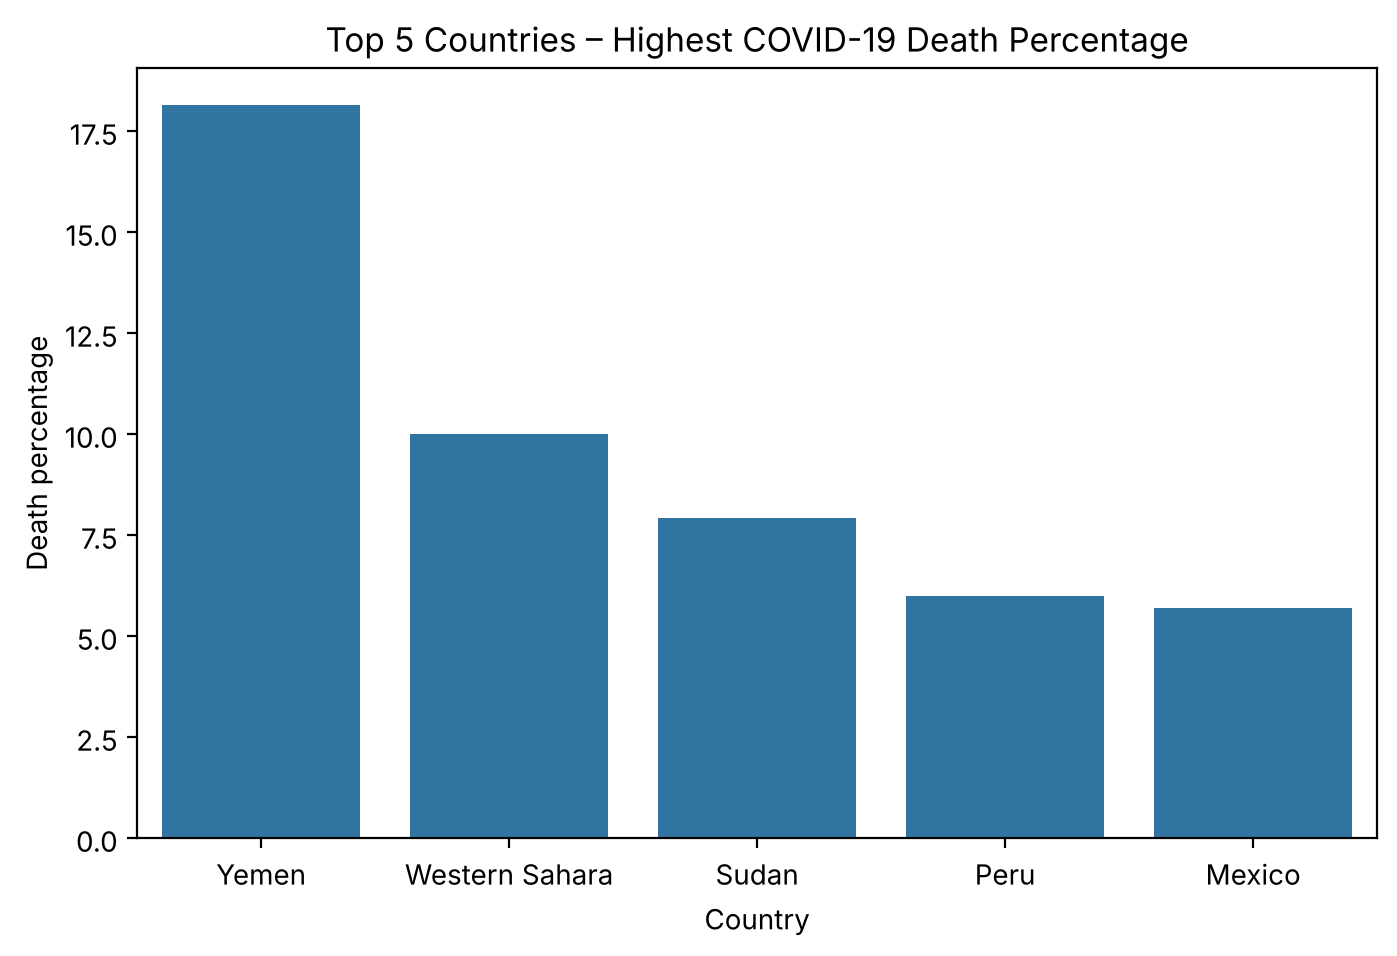

In [20]:
plt.figure(figsize=(8,5))
sns.barplot(x='Country', y='Death percentage', data=top_dp)
plt.title('Top 5 Countries – Highest COVID-19 Death Percentage')
plt.show()

### 21. Continent-wise total cases using groupby()

In [21]:
continent_cases = df.groupby('Continent')['Total Cases'].sum()
continent_cases

Continent
Africa                              11764207
Asia                               140957179
Europe                             180332483
Latin America and the Caribbean     67509231
Northern America                    85364770
Oceania                              5647957
Name: Total Cases, dtype: int64

### 22. Reset index and bar plot

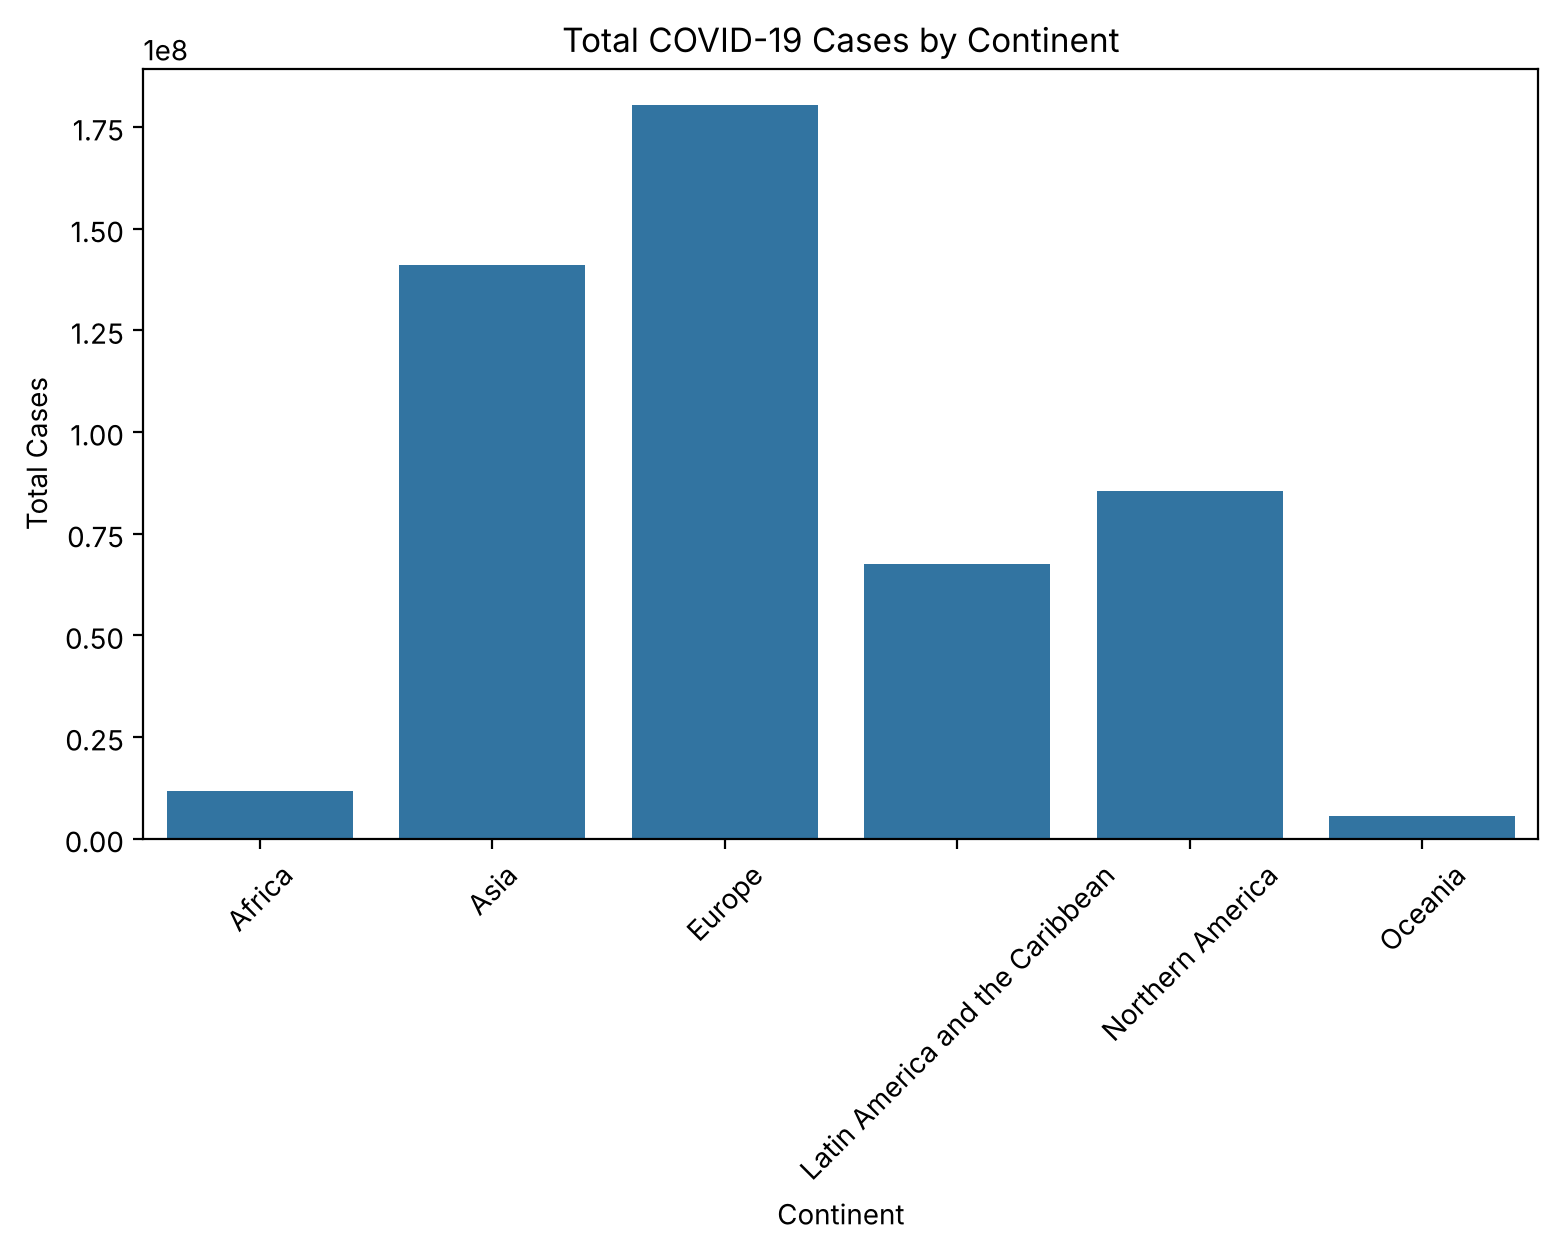

In [22]:
continent_cases = continent_cases.reset_index()
plt.figure(figsize=(9,5))
sns.barplot(x='Continent', y='Total Cases', data=continent_cases)
plt.title('Total COVID-19 Cases by Continent')
plt.xticks(rotation=45)
plt.show()

### 23. Scatter plot – Population vs Total Cases

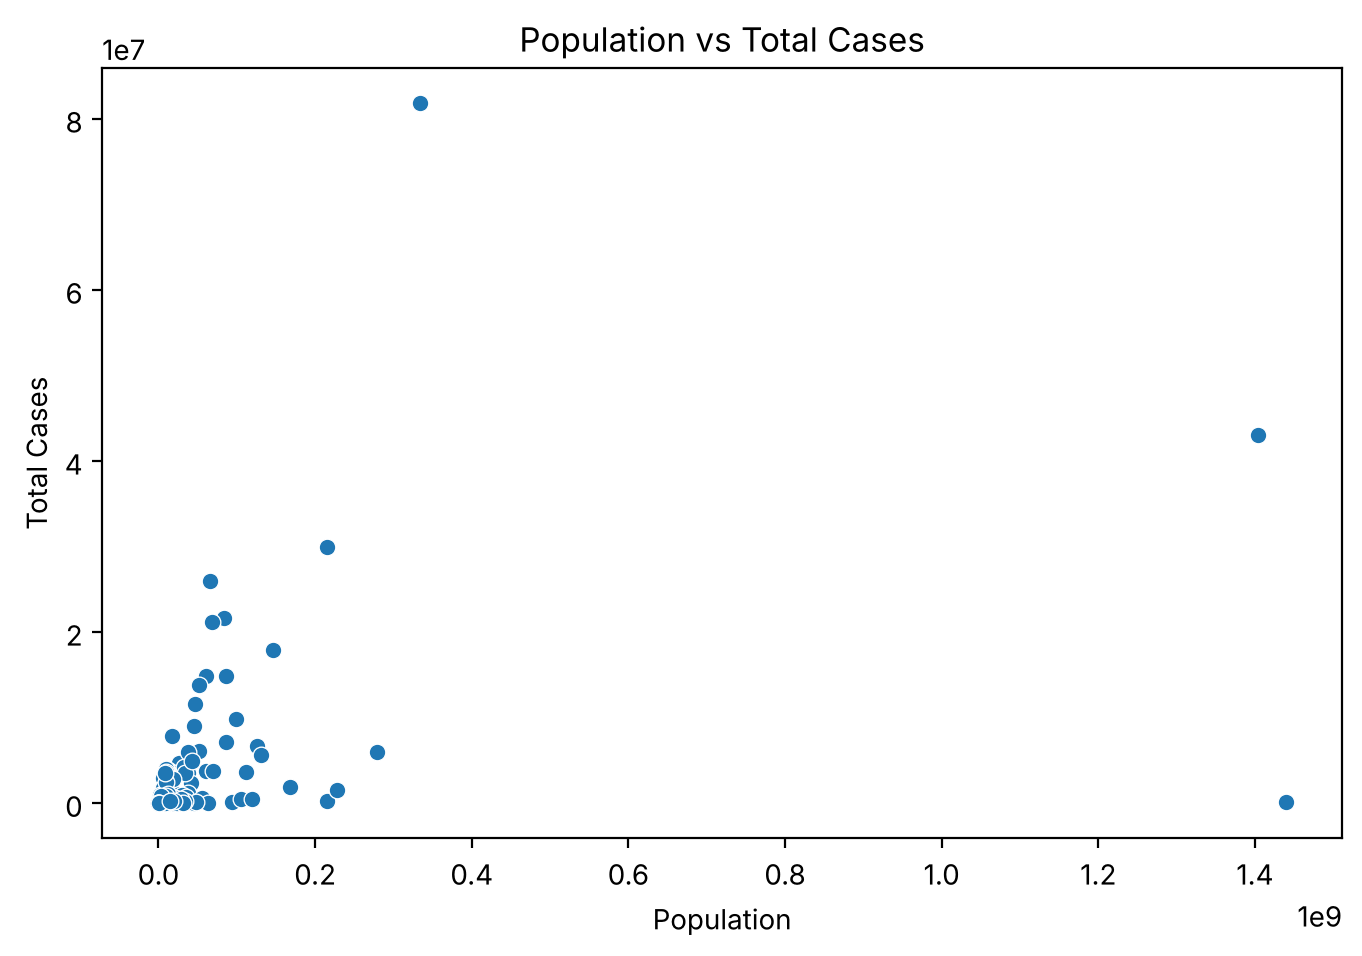

In [23]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='Population', y='Total Cases', data=df)
plt.title('Population vs Total Cases')
plt.show()

### 24. Scatter plot – Total Cases vs Total Deaths

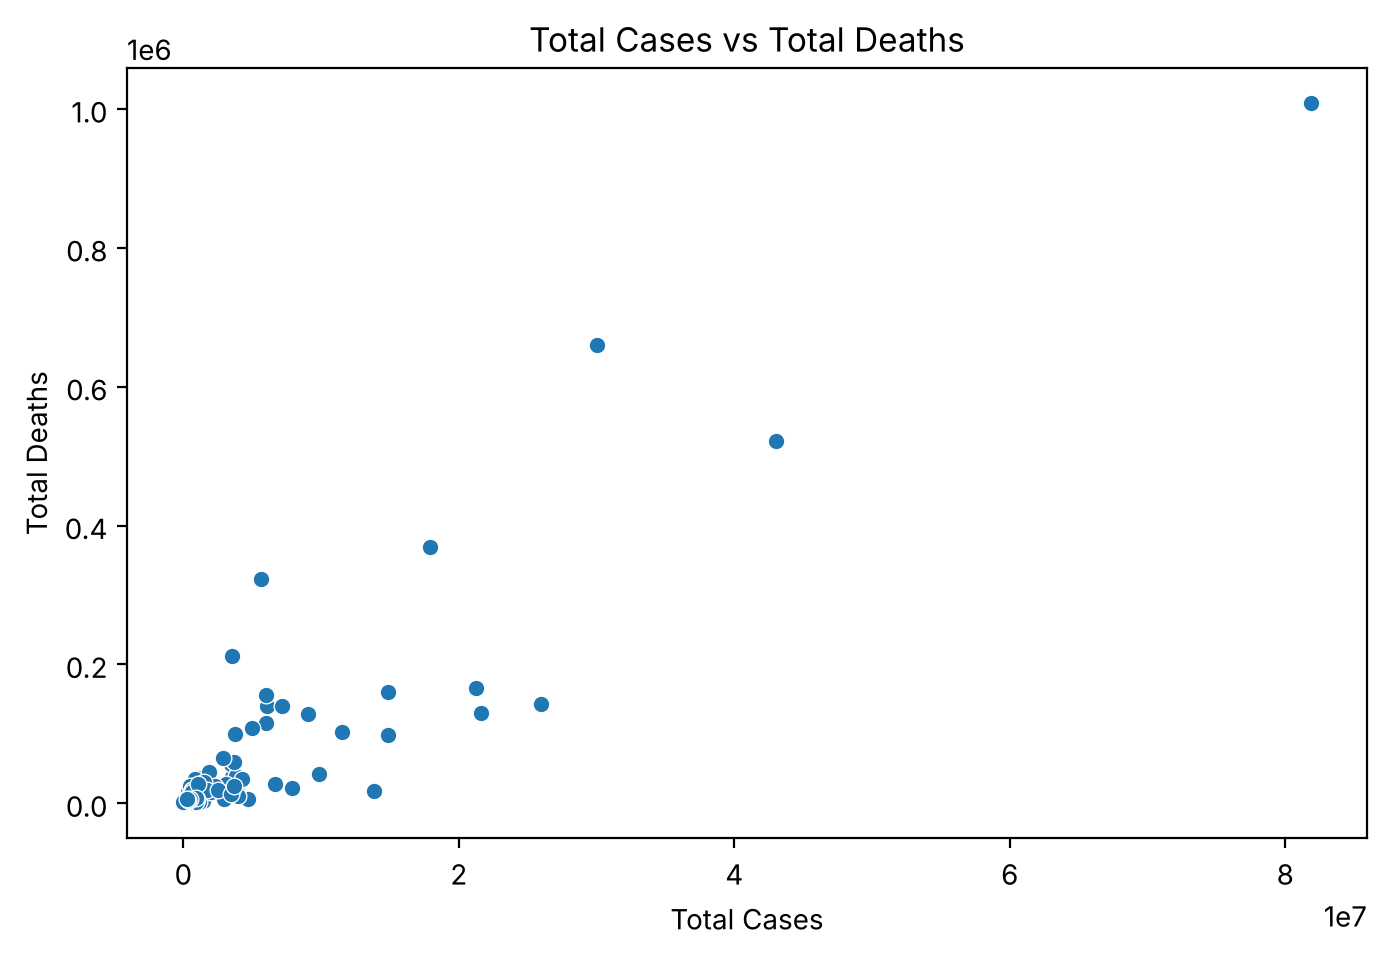

In [24]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='Total Cases', y='Total Deaths', data=df)
plt.title('Total Cases vs Total Deaths')
plt.show()

### 25. Spearman correlation + heatmap

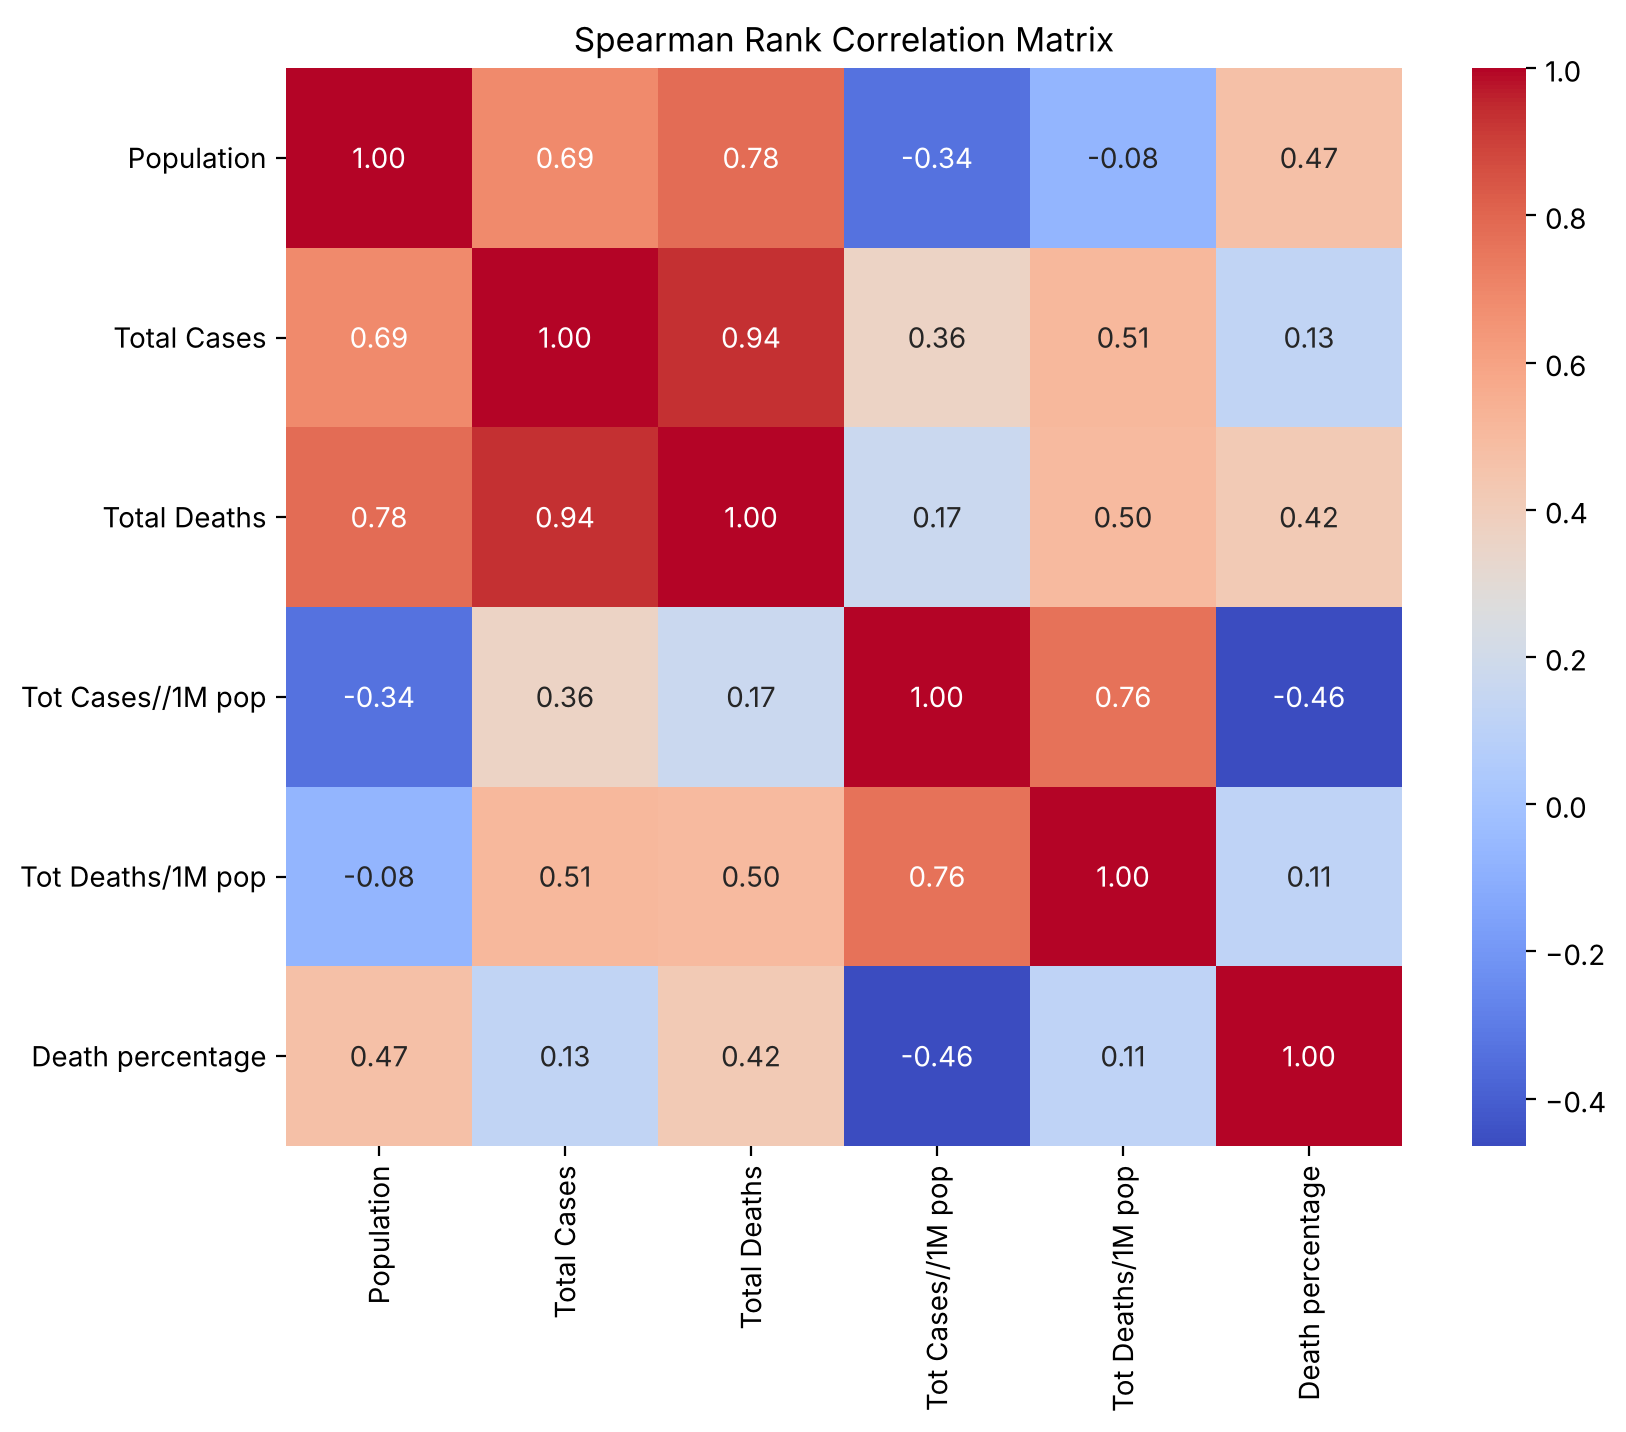

,Population,Total Cases,Total Deaths,Tot Cases//1M pop,Tot Deaths/1M pop,Death percentage
Population,1.000000,0.687202,0.777911,-0.337995,-0.075012,0.473551
Total Cases,0.687202,1.000000,0.936754,0.360762,0.508911,0.125393
Total Deaths,0.777911,0.936754,1.000000,0.165149,0.497638,0.420970
Tot Cases//1M pop,-0.337995,0.360762,0.165149,1.000000,0.760715,-0.464251
Tot Deaths/1M pop,-0.075012,0.508911,0.497638,0.760715,1.000000,0.113898
Death percentage,0.473551,0.125393,0.420970,-0.464251,0.113898,1.000000


In [25]:
corr = df.select_dtypes(include='number').corr(method='spearman')
plt.figure(figsize=(9,7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Spearman Rank Correlation Matrix')
plt.show()
corr